
# Artificial Neural Networks for Breast Cancer Classification

**Course:** Advanced Machine Learning (AML)  
**Methodology:** Team Data Science Process (TDSP)  
**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC)  
**Reference Article:** Artificial Neural Network with Taguchi Method for Robust Classification Model to Improve Classification Accuracy of Breast Cancer (2021).


**Group Members:**

-Khadija Bessais

-Emna Jbari 

-Youssef Gomri

-Aymen Fkir

-Rayen Sayari

-Fares Ben Kheder 




## 1. Business Understanding

### 1.1 Business Objectives

Développer un système intelligent d'aide à la classification des tumeurs mammaires afin de contribuer à une détection plus fiable du cancer du sein, en réduisant les erreurs de classification et en améliorant la précision du diagnostic assisté par ordinateur.

### 1.2 Data Science Objectives

- Reproduire le modèle ANN optimisé par la méthode Taguchi proposé dans l'article de Rahman et al. (2021), en utilisant le dataset Wisconsin Diagnostic Breast Cancer, afin de retrouver des performances similaires à celles publiées (98,8 % d'accuracy), puis expérimenter différentes techniques de prétraitement et d'optimisation pour améliorer la précision, la robustesse et la capacité de généralisation du modèle.
- Analyze misclassifications and compare where the baseline approach struggles such as overlapping regions in feature or component space.
- Compare enhanced models against the paper baseline across consistent metrics (and statistical/stability checks across folds) to document what genuinely improves performance and why.

## 2. Data Acquisition and Understanding

#### Libraries and imports

In [ ]:
!pip install ucimlrepo

### 2.1 Data Loading


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
from ucimlrepo import fetch_ucirepo


### 2.2 Dataset Description

### Overview & Origin

* **Domain & Task:** A multivariate **Health and Medicine** dataset designed for **classification** tasks.
* **Data Source:** Features are computed from digitized images of a **fine needle aspirate (FNA)** of a breast mass, describing characteristics of the cell nuclei present in the image.
* **Size & Completeness:** Contains **569 instances** (samples) and **30 real-valued (continuous) features**, with **no missing values** (plus an `ID` column and a `Diagnosis` target column).
* **Creators & History:** Created by William Wolberg, Olvi Mangasarian, Nick Street, and W. Street (introduced in their 1993 paper *"Nuclear feature extraction for breast tumor diagnosis"*) and donated to UCI on October 31, 1995.

### Target Variable

* **`Diagnosis`:** Categorical target with two classes:
* **`M`** = Malignant
* **`B`** = Benign



### The 30 Features (10 Nuclear Measurements × 3 Summary Groups)

Ten real-valued characteristics are computed for each cell nucleus:

1. **Radius:** Mean of distances from the center to points on the perimeter.
2. **Texture:** Standard deviation of gray-scale values.
3. **Perimeter:** Cell nucleus perimeter.
4. **Area:** Cell nucleus area.
5. **Smoothness:** Local variation in radius lengths.
6. **Compactness:** $\text{perimeter}^2 / \text{area} - 1.0$.
7. **Concavity:** Severity of concave portions of the contour.
8. **Concave points:** Number of concave portions of the contour.
9. **Symmetry:** Symmetry of the cell nucleus.
10. **Fractal dimension:** "Coastline approximation" $- 1$.

In your dataset, each of these 10 measurements appears across **three groups** (corresponding to the suffixes `1`, `2`, and `3` in your column names, representing mean, standard error/SE, and worst/largest values), giving $10 \times 3 = 30$ features in total.

### Citation

> Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. [https://doi.org/10.24432/C5DW2B](https://doi.org/10.24432/C5DW2B) (Licensed under CC BY 4.0).

### 2.3 Data Acquisition


In [5]:
# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

data = pd.concat([X, y], axis=1)

### 2.4 Dataset Structure


In [6]:
data.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


### 2.5 Exploratory Data Analysis (EDA)

#### 2.5.1 Dataset Dimensions


In [7]:
data.shape

(569, 31)

#### 2.5.2 Feature Types


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavit

#### 2.5.3 Target Variable Distribution


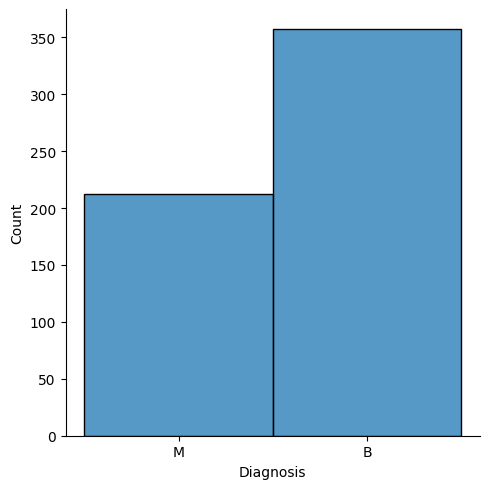

In [12]:
sns.displot(data['Diagnosis'], kde=False, bins=30)

#### 2.5.4 Missing Values and Duplicates


In [17]:
data.isna().any()

radius1               False
texture1              False
perimeter1            False
area1                 False
smoothness1           False
compactness1          False
concavity1            False
concave_points1       False
symmetry1             False
fractal_dimension1    False
radius2               False
texture2              False
perimeter2            False
area2                 False
smoothness2           False
compactness2          False
concavity2            False
concave_points2       False
symmetry2             False
fractal_dimension2    False
radius3               False
texture3              False
perimeter3            False
area3                 False
smoothness3           False
compactness3          False
concavity3            False
concave_points3       False
symmetry3             False
fractal_dimension3    False
Diagnosis             False
dtype: bool

In [24]:
data.duplicated().any()

np.False_

#### 2.5.5 Statistical Summary


In [25]:
data.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


#### 2.5.6 Feature Correlation Analysis

Strong positive correlations (~0.7 to 1.0) cluster within size (radius, perimeter, area) and shape complexity features, with only mild negative correlations .

High redundancy across correlated features explains why PCA can summarize the 30 features into a few components with minimal information loss .

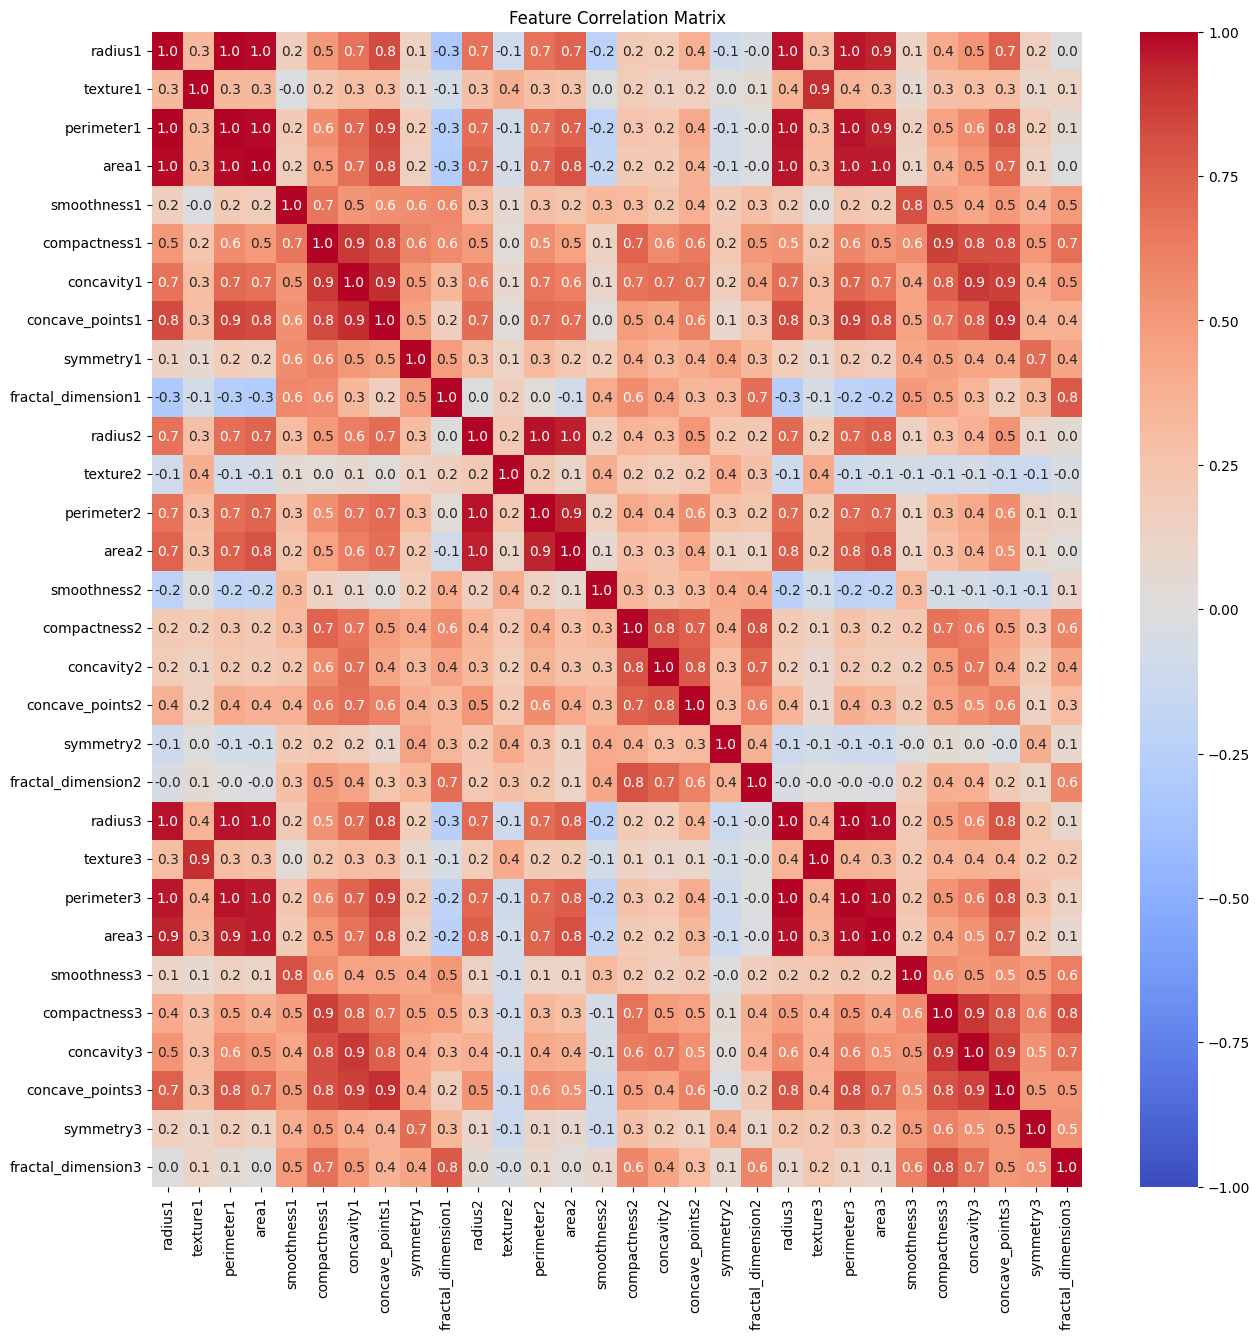

In [26]:
numeric_df = data.select_dtypes(include=['number'])
corr_matrix_pd = numeric_df.corr(method='pearson')
plt.figure(figsize=(15, 15))
sns.heatmap(corr_matrix_pd, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".1f")
plt.title("Feature Correlation Matrix")
plt.show()


In [27]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=0.9)
pca.fit(X_scaled)

,n_components,0.9
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [28]:
shape = pca.components_.T.shape
columns = [f"PCA_{i}" for i in range(1, shape[1] + 1)]
components_df = pd.DataFrame(pca.components_.T, columns=columns,index=X.columns)
components_df

,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7
radius1,0.218902,-0.233857,-0.008531,-0.041409,-0.037786,0.018741,-0.124088
texture1,0.103725,-0.059706,0.064550,0.603050,0.049469,-0.032179,0.011400
perimeter1,0.227537,-0.215181,-0.009314,-0.041983,-0.037375,0.017308,-0.114477
area1,0.220995,-0.231077,0.028700,-0.053434,-0.010331,-0.001888,-0.051653
smoothness1,0.142590,0.186113,-0.104292,-0.159383,0.365089,-0.286374,-0.140669
compactness1,0.239285,0.151892,-0.074092,-0.031795,-0.011704,-0.014131,0.030918
concavity1,0.258400,0.060165,0.002734,-0.019123,-0.086375,-0.009344,-0.107520
concave_points1,0.260854,-0.034768,-0.025564,-0.065336,0.043861,-0.052050,-0.150482
symmetry1,0.138167,0.190349,-0.040240,-0.067125,0.305941,0.356458,-0.093891
fractal_dimension1,0.064363,0.366575,-0.022574,-0.048587,0.044424,-0.119431,0.295760


PCA_4 is strongly driven by texture3 (0.63) and texture1 (0.60), while PCA_6 is led by symmetry3 (0.50) and symmetry2 (0.49)[cite: 2].

Later components (PCA_2 through PCA_7) capture distinct feature groups and opposing signs rather than a single dominant feature[cite: 2].

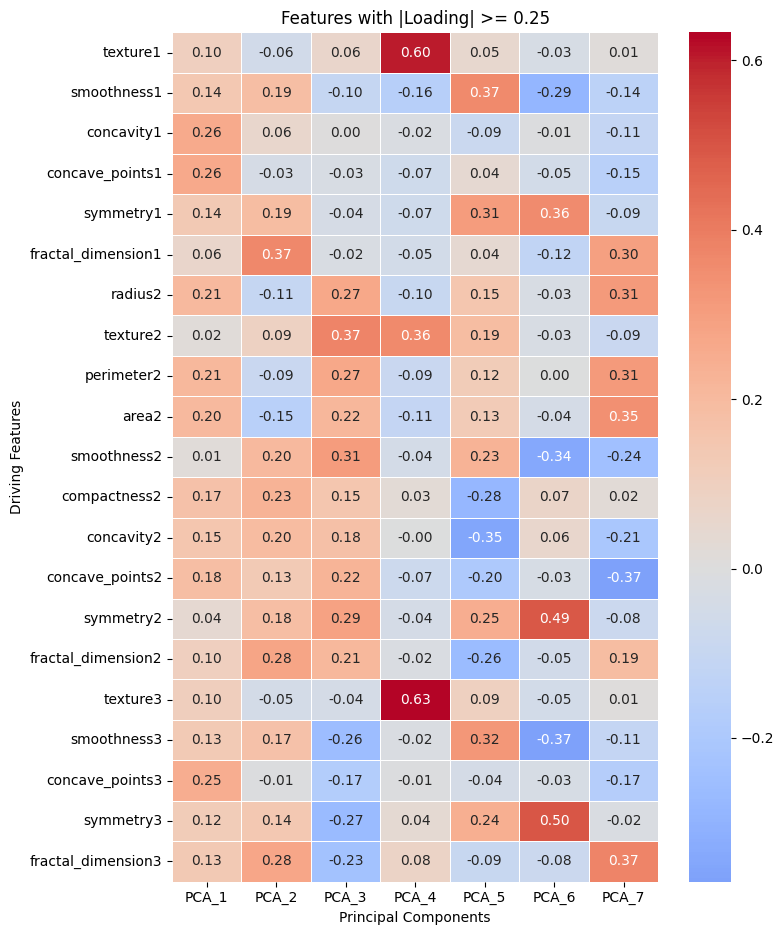

In [29]:
threshold = 0.25
driving_mask = (components_df.abs() >= threshold).any(axis=1)
filtered_df = components_df.loc[driving_mask]

plt.figure(figsize=(8, max(5, len(filtered_df) * 0.45)))
sns.heatmap(
    filtered_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)
plt.title(f"Features with |Loading| >= {threshold}")
plt.xlabel("Principal Components")
plt.ylabel("Driving Features")
plt.tight_layout()
plt.show()

PC1 captures the largest share (~44%) followed by PC2 (~19%), while each later component contributes under 10%.

Cumulative coverage reaches ~79% at PC4 and crosses the 80% threshold at PC5 (reaching ~91% by PC7).

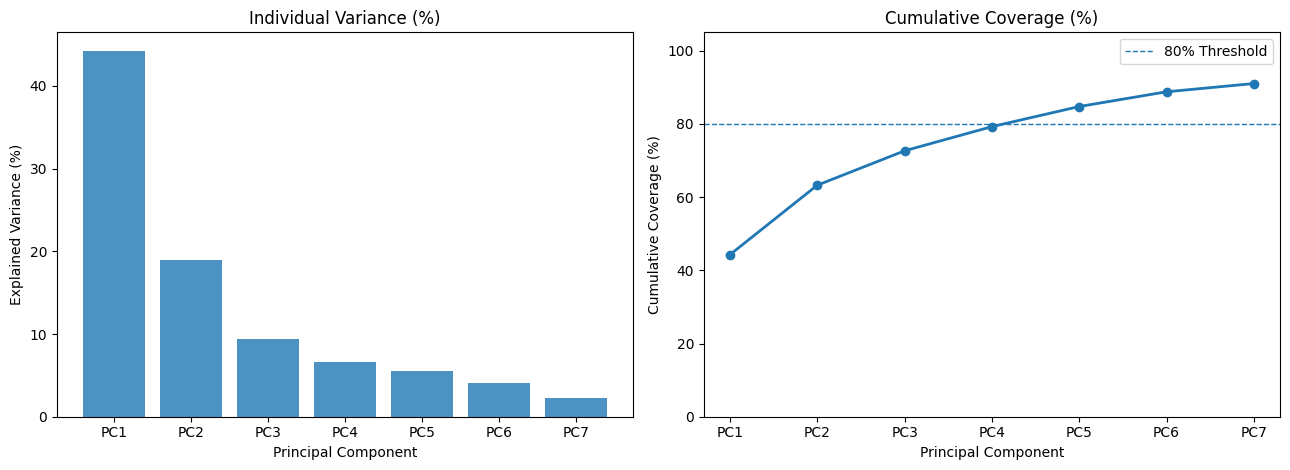

In [30]:
explained = pca.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)
x = np.arange(1, len(explained) + 1)
labels = [f"PC{i}" for i in x]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: Individual explained variance
ax1.bar(x, explained, alpha=0.8)
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance (%)")
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_title("Individual Variance (%)")

# Right: Cumulative coverage
ax2.plot(x, cumulative, marker="o", linewidth=2)
ax2.set_xlabel("Principal Component")
ax2.set_ylabel("Cumulative Coverage (%)")
ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.set_ylim(0, 105)
ax2.axhline(80, linestyle="--", linewidth=1, label="80% Threshold")
ax2.set_title("Cumulative Coverage (%)")
ax2.legend()

fig.tight_layout()
plt.show()

In [31]:
pca4 = PCA(n_components=4)
X_pca4 = pca4.fit_transform(X_scaled)

pca_cols = ["PCA_1", "PCA_2", "PCA_3", "PCA_4"]
X_pca4_df = pd.DataFrame(X_pca4, columns=pca_cols, index=X.index)

pca_data = pd.concat([X_pca4_df, y], axis=1)
pca_data.head()

,PCA_1,PCA_2,PCA_3,PCA_4,Diagnosis
0,9.192837,1.948583,-1.123166,-3.633731,M
1,2.387802,-3.768172,-0.529293,-1.118264,M
2,5.733896,-1.075174,-0.551748,-0.912083,M
3,7.122953,10.275589,-3.232790,-0.152547,M
4,3.935302,-1.948072,1.389767,-2.940639,M


PCA_1 gives the clearest separation between malignant (M) and benign (B) cases, with M generally scoring higher than B.

PCA_2 through PCA_4 show heavy overlap between M and B, though they capture subtle spread and a few high-value outliers .

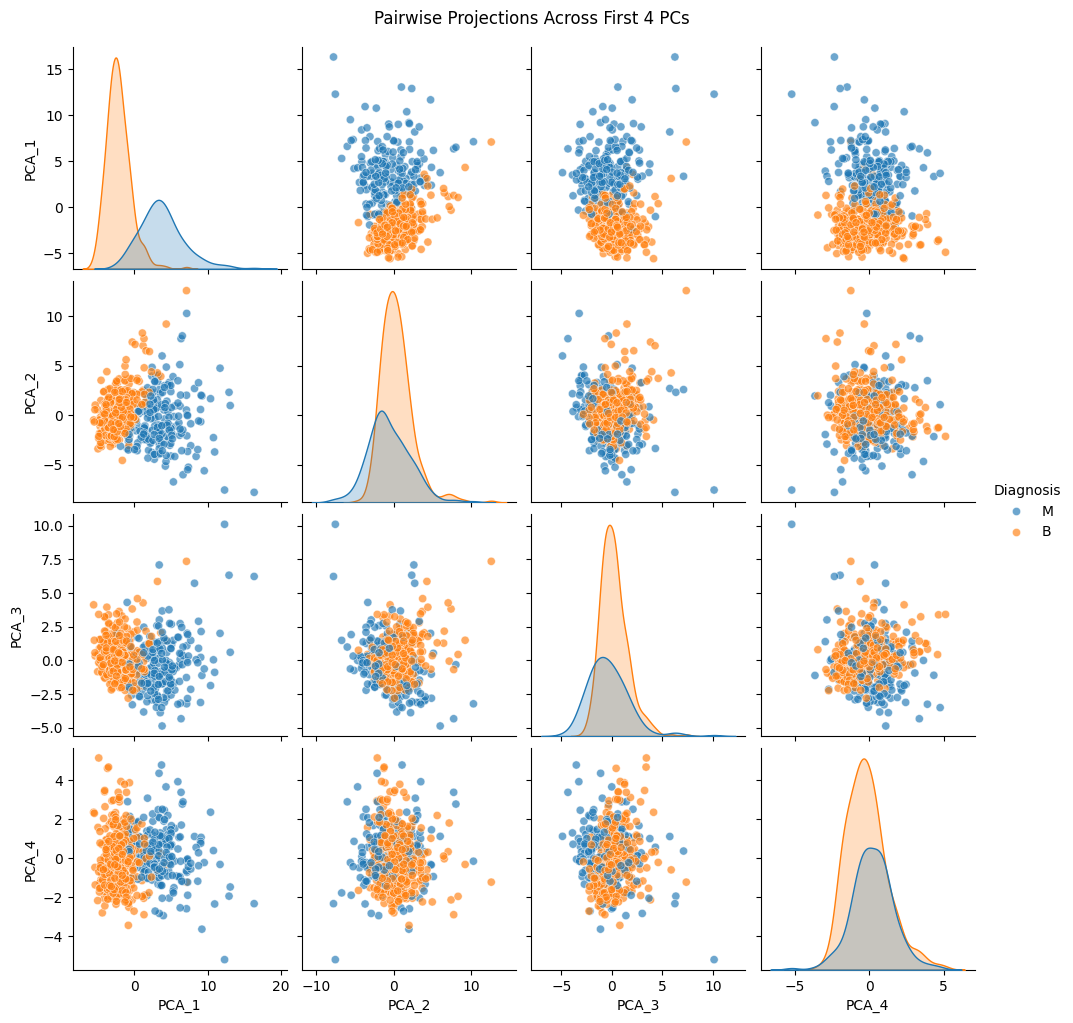

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(
    pca_data,
    vars=pca_cols,
    hue="Diagnosis",
    plot_kws={"alpha": 0.65, "s": 35},
    diag_kind="kde",
)
plt.suptitle("Pairwise Projections Across First 4 PCs", y=1.02)
plt.show()

Most feature vectors point toward positive PCA_1 where malignant (M) cases cluster, while fractal_dimension1 pulls upward along positive PCA_2 .

Top-ranked vectors (Plot 1) have the longest reach in the PCA_1/PCA_2 plane, whereas lower-ranked vectors (Plots 5–6) are shorter and more concentrated near the origin .

Plot 1 (ranks 1–5): ['fractal_dimension1', 'radius1', 'area1', 'radius3', 'area3']
Plot 2 (ranks 6–10): ['perimeter1', 'perimeter3', 'fractal_dimension3', 'fractal_dimension2', 'compactness2']
Plot 3 (ranks 11–15): ['compactness1', 'concavity1', 'concave_points1', 'compactness3', 'area2']
Plot 4 (ranks 16–20): ['concave_points3', 'concavity2', 'concavity3', 'symmetry1', 'smoothness1']
Plot 5 (ranks 21–25): ['radius2', 'perimeter2', 'concave_points2', 'smoothness3', 'smoothness2']
Plot 6 (ranks 26–30): ['symmetry2', 'symmetry3', 'texture1', 'texture3', 'texture2']


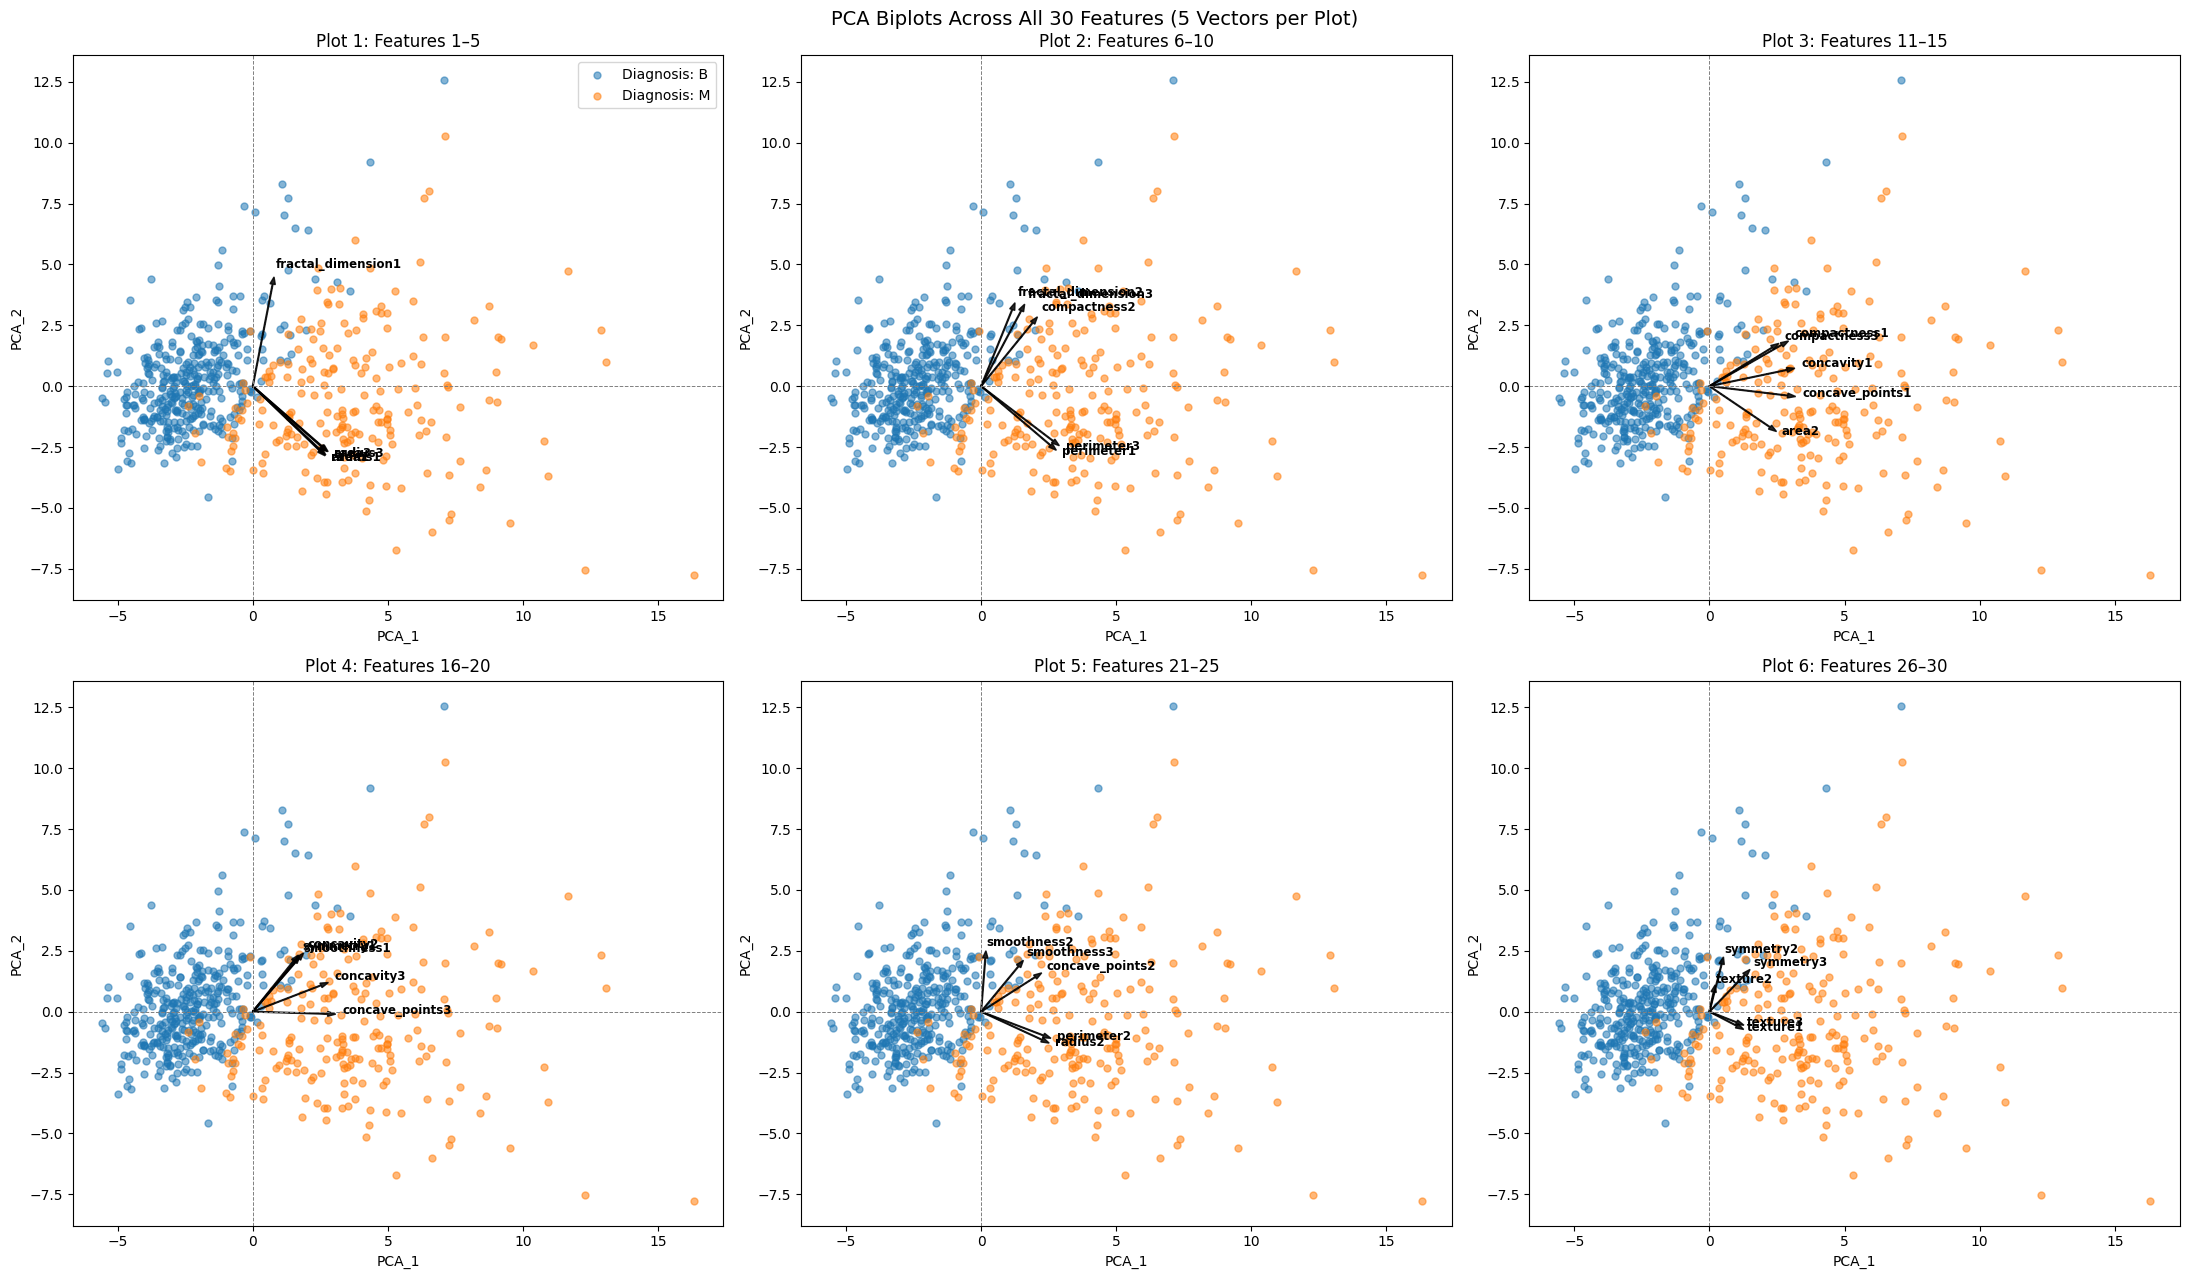

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Loadings for PCA_1 and PCA_2 -> shape (30, 2)
loadings = pca4.components_[:2].T
scale = np.max(np.abs(pca_data[["PCA_1", "PCA_2"]].values)) * 0.75

# Rank all 30 features from strongest to weakest on (PCA_1, PCA_2)
strength = np.linalg.norm(loadings, axis=1)
ranked_idx = np.argsort(strength)[::-1]  # strongest first

fig, axes = plt.subplots(2, 3, figsize=(22, 13))
axes = axes.ravel()

for plot_i in range(6):
  ax = axes[plot_i]
  start = plot_i * 5
  end = start + 5
  group_idx = ranked_idx[start:end]

  # Scatter of transformed samples
  for diag, grp in pca_data.groupby("Diagnosis"):
    ax.scatter(
        grp["PCA_1"],
        grp["PCA_2"],
        label=f"Diagnosis: {diag}",
        alpha=0.55,
        s=25,
    )

  shown_features = []
  for idx in group_idx:
    dx, dy = loadings[idx] * scale
    ax.arrow(
        0,
        0,
        dx,
        dy,
        color="black",
        alpha=0.85,
        width=0.03,
        head_width=0.20,
        length_includes_head=True,
    )
    ax.text(
        dx * 1.08,
        dy * 1.08,
        X.columns[idx],
        fontsize=8.5,
        fontweight="bold",
        color="black",
    )
    shown_features.append(X.columns[idx])

  ax.axhline(0, color="gray", linestyle="--", linewidth=0.7)
  ax.axvline(0, color="gray", linestyle="--", linewidth=0.7)
  ax.set_xlabel("PCA_1")
  ax.set_ylabel("PCA_2")
  ax.set_title(f"Plot {plot_i + 1}: Features {start + 1}–{end}")
  if plot_i == 0:
    ax.legend()

  print(f"Plot {plot_i + 1} (ranks {start + 1}–{end}): {shown_features}")

plt.suptitle("PCA Biplots Across All 30 Features (5 Vectors per Plot)", fontsize=14)
plt.tight_layout()
plt.show()